In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df =  pd.read_csv("/content/amz_uk_price_prediction_dataset.csv")
df.head(3)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers


**Part 1**: Analyzing Best-Seller Trends Across Product Categories:

1. Crosstab Analysis:

- Create a crosstab between the product category and the isBestSeller status.

- Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

2. Statistical Tests:

- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
- Compute Cramér's V to understand the strength of association between best-seller status and category.
Visualizations:

- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [11]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [12]:
best_seller_prop = (
    crosstab
    .div(crosstab.sum(axis=1), axis=0)[True]
    .sort_values(ascending=False)
)

# Top 10 categories
top_10_categories = best_seller_prop.head(10)
top_10_categories

,True
category,
Grocery,0.058135
Smart Home Security & Lighting,0.057692
Health & Personal Care,0.057686
Mobile Phone Accessories,0.042471
Power & Hand Tools,0.035339
"Billiard, Snooker & Pool",0.032129
Pet Supplies,0.030200
Home Brewing & Wine Making,0.028455
Mirrors,0.028000


In [13]:
from scipy.stats import chi2_contingency

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(crosstab)

chi2, p_value, dof

# Not independent

(np.float64(36540.20270061387), np.float64(0.0), 295)

In [14]:
n = crosstab.to_numpy().sum()
min_dim = min(crosstab.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))
cramers_v

# Small to moderate association between product category and best-seller status.

np.float64(0.1222829439760564)

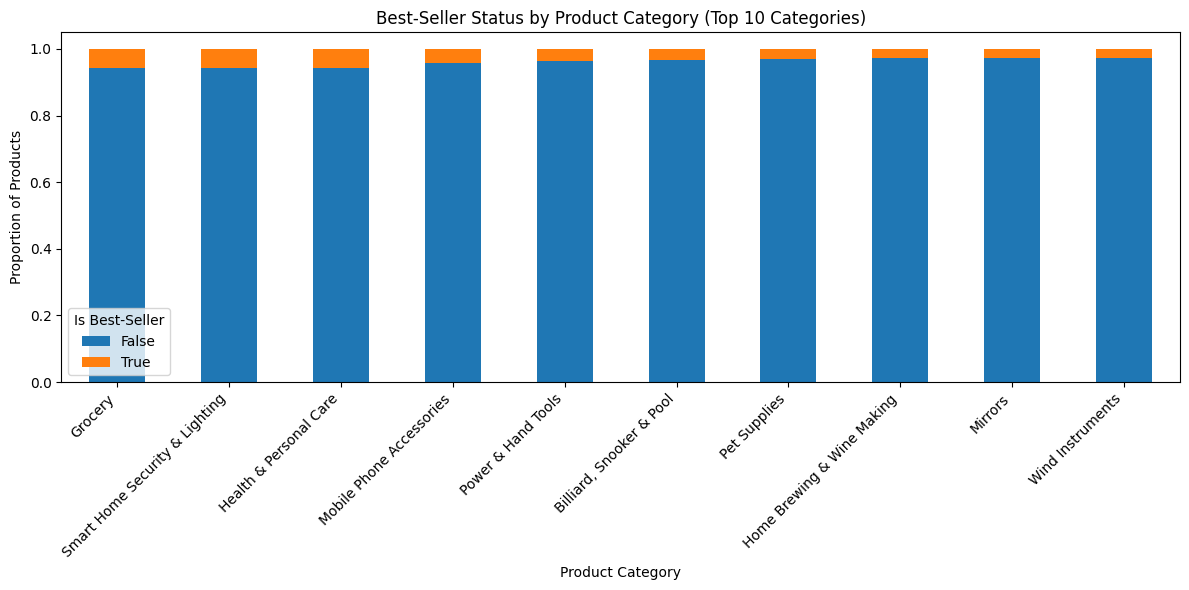

In [15]:
category_props = crosstab.div(crosstab.sum(axis=1), axis=0)


top_10 = category_props.loc[
    category_props[True].sort_values(ascending=False).head(10).index
]

# Stacked bar chart
top_10.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("Best-Seller Status by Product Category (Top 10 Categories)")
plt.ylabel("Proportion of Products")
plt.xlabel("Product Category")
plt.legend(title="Is Best-Seller")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Part 2**: Exploring Product Prices and Ratings Across Categories and Brands
Objective: Investigate how different product categories influence product prices.

0. Preliminary Step: Remove outliers in product prices.

- For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

1. Violin Plots:

- Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.

2. Bar Charts:

- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
- Which product category commands the highest average price? Don't filter here by top categories.

3. Box Plots:

- Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.




In [16]:
df['price'].describe()

,price
count,2.443651e+06
mean,8.924381e+01
std,3.456089e+02
min,0.000000e+00
25%,9.990000e+00
50%,1.909000e+01
75%,4.599000e+01
max,1.000000e+05


In [17]:
df['price'] = pd.to_numeric(df['price'], errors='coerce')

In [18]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

Q1, Q3, lower_bound, upper_bound

(np.float64(9.99),
 np.float64(45.99),
 np.float64(-44.01),
 np.float64(99.99000000000001))

In [19]:
df_no_outliers = df[
    (df['price'] >= lower_bound) &
    (df['price'] <= upper_bound)
].copy()

In [20]:
print("Original dataset size:", df.shape)
print("After outlier removal:", df_no_outliers.shape)

Original dataset size: (2443651, 9)
After outlier removal: (2115963, 9)


In [21]:
top_20_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

df_top20 = df_no_outliers[df_no_outliers['category'].isin(top_20_categories)]

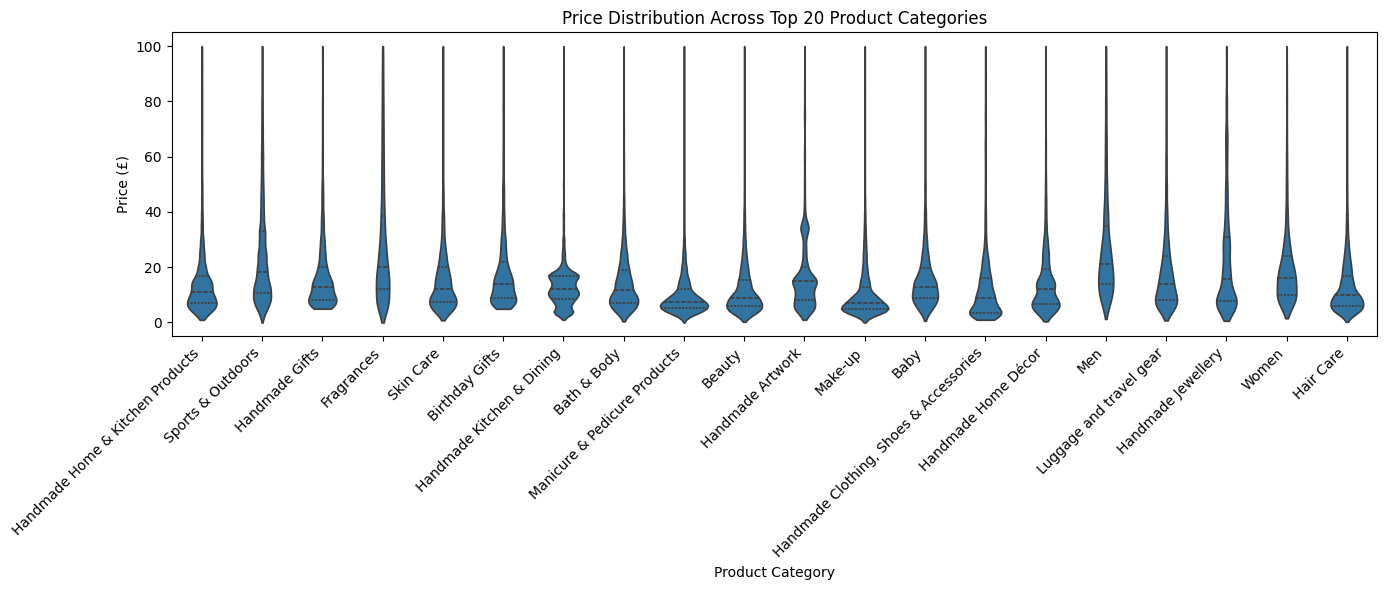

In [22]:
plt.figure(figsize=(14, 6))

sns.violinplot(
    data=df_top20,
    x='category',
    y='price',
    inner='quartile',
    cut=0)

plt.xticks(rotation=45, ha='right')
plt.title("Price Distribution Across Top 20 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()

In [23]:
top_10_categories = df_no_outliers['category'].value_counts().head(10).index

# Average price for top 10 categories
avg_prices_top10 = (
    df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False))

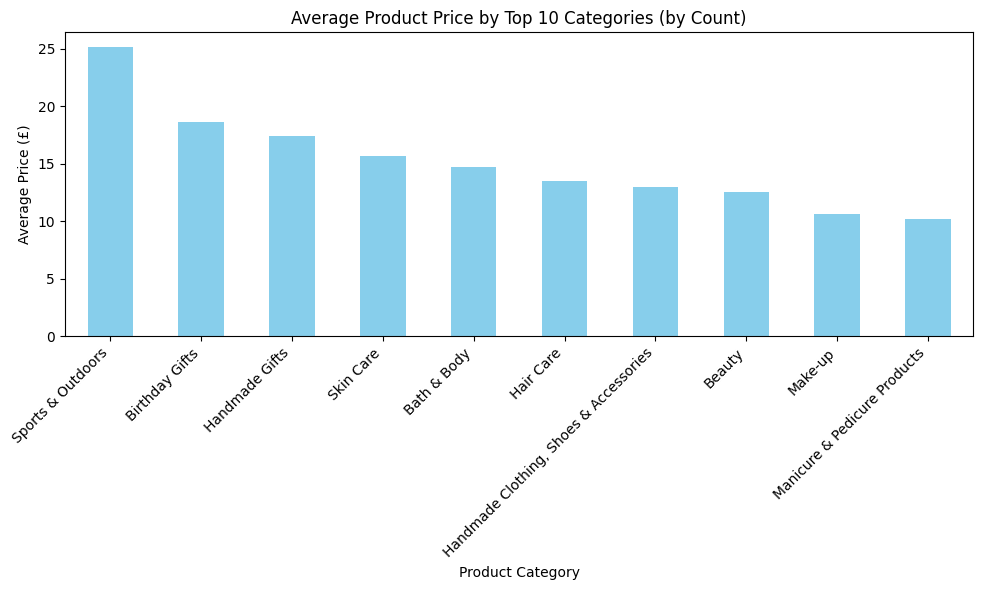

In [24]:
plt.figure(figsize=(10,6))
avg_prices_top10.plot(kind='bar', color='skyblue')

plt.title("Average Product Price by Top 10 Categories (by Count)")
plt.ylabel("Average Price (£)")
plt.xlabel("Product Category")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [25]:
top_10_categories = df_no_outliers['category'].value_counts().head(10).index

df_top10 = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]

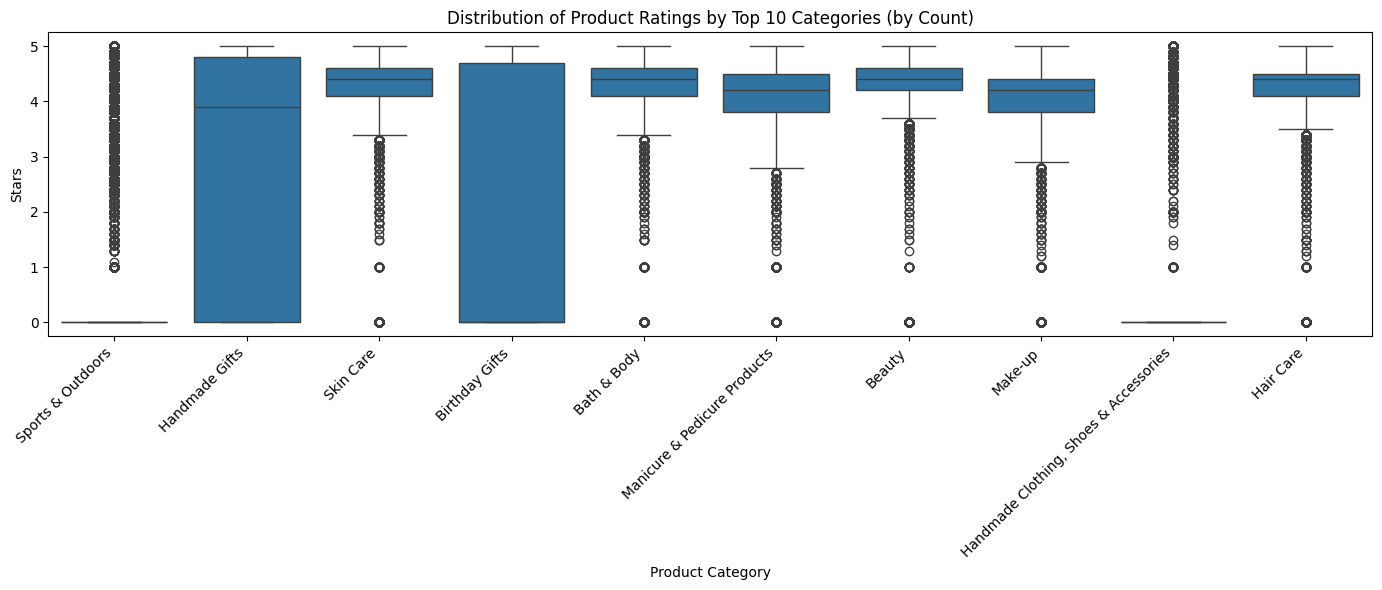

In [27]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df_top10,
    x='category',
    y='stars'
)

plt.xticks(rotation=45, ha='right')
plt.title("Distribution of Product Ratings by Top 10 Categories (by Count)")
plt.xlabel("Product Category")
plt.ylabel("Stars")
plt.tight_layout()
plt.show()

**Part 3**: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

1. Correlation Coefficients:

- Calculate the correlation coefficient between price and stars.
- Is there a significant correlation between product price and its rating?

2. Visualizations:

- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
- Examine if product prices typically follow a normal distribution using a QQ plot.

In [29]:
df_no_outliers['price'] = pd.to_numeric(df_no_outliers['price'], errors='coerce')
df_no_outliers['stars'] = pd.to_numeric(df_no_outliers['stars'], errors='coerce')

# Drop any rows with missing values
df_corr = df_no_outliers.dropna(subset=['price', 'stars'])

In [31]:
# Pearson correlation
corr = df_corr['price'].corr(df_corr['stars'])
corr

np.float64(-0.07767299878181352)

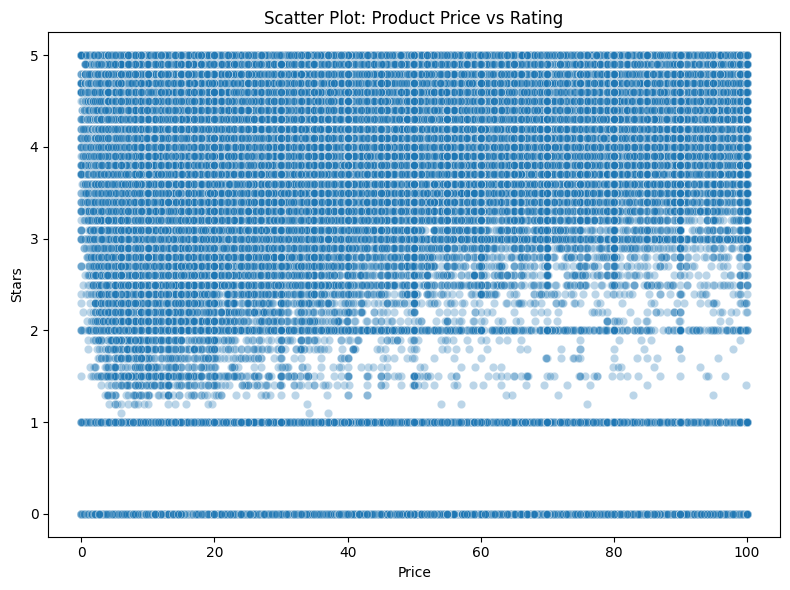

In [32]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_no_outliers,
    x='price',
    y='stars',
    alpha=0.3
)
plt.title("Scatter Plot: Product Price vs Rating")
plt.xlabel("Price")
plt.ylabel("Stars")
plt.tight_layout()
plt.show()

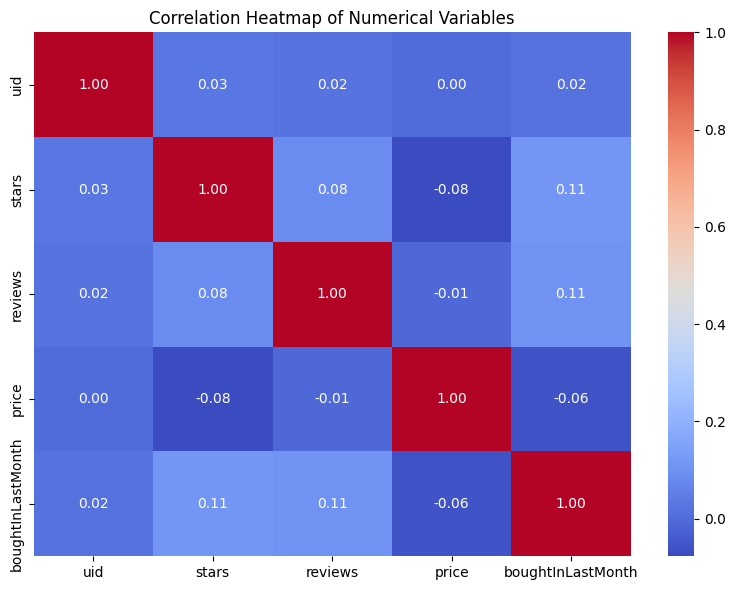

In [33]:
plt.figure(figsize=(8,6))
numerical_cols = df_no_outliers.select_dtypes(include='number')

sns.heatmap(
    numerical_cols.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

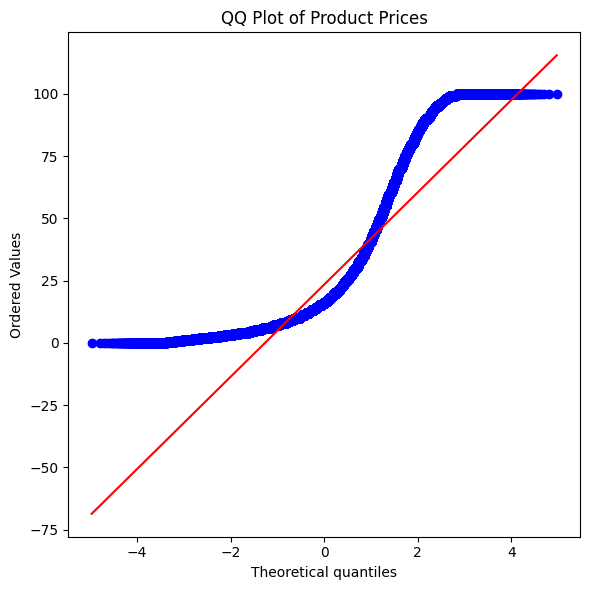

In [35]:
from scipy import stats
plt.figure(figsize=(6,6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.tight_layout()
plt.show()